# Повышение разрешения изображений с помощью SRGAN

**Задача.** На вход подаётся изображение низкого разрешения (.png, .bmp, .jpg), на выходе - то же изображение в 4 раза большего разрешения с восстановленными деталями.

**Подход.** SRGAN ([Ledig et al., 2017](https://arxiv.org/abs/1609.04802)) - генеративно-состязательная сеть для super-resolution. Обучается в два этапа:
1. **SRResNet** - генератор учится только на попиксельной ошибке (MSE). Даёт высокий PSNR, но картинка получается «мыльной».
2. **SRGAN** - генератор дообучается вместе с дискриминатором на perceptual loss. Детали выглядят резче и естественнее.

**Содержание.** 1 Настройка · 2 Датасет · 3 Модель · 4 Метрики · 5 Обучение · 6 Оценка на тесте · 7 Применение к своим картинкам · 8 Выводы


## 1. Настройка

In [ ]:
import csv
import json
import platform
import random
import shutil
import sys
import threading
import time
import warnings
import zipfile
from collections import defaultdict, deque
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import Image, Markdown, display
from torch.optim import Adam
from torch.optim.lr_scheduler import MultiStepLR
from torchvision.models import VGG19_Weights, vgg19
from tqdm import tqdm as _tqdm


def tqdm(*args, **kwargs):
    return _tqdm(*args, file=sys.stdout, mininterval=1.0, dynamic_ncols=True, **kwargs)

In [ ]:
# True - быстрая проверка пайплайна, False - полное обучение
SMOKE = False

TASK_DIR = Path.cwd()
assert (TASK_DIR / "srgan.ipynb").exists(), "Ноутбук нужно запускать из папки task-1-super-resolution"
RAW = TASK_DIR / "data" / "raw" / "APISR_Dataset.zip"            
DATA = TASK_DIR / "data" / ("smoke" if SMOKE else "prepared")      
RESULTS = TASK_DIR / "results" / "smoke" if SMOKE else TASK_DIR / "results"   
WEIGHTS = RESULTS / "weights" if SMOKE else TASK_DIR / "weights"   
CKPT = TASK_DIR / "checkpoints" / ("smoke" if SMOKE else "")       

SCALE = 4
SEED = 42

DATA_CFG = dict(val=20, test=100, crop=480, step=480, min_std=5.0, min_size=128, limit=None, threads=8)
TRAIN_CFG = dict(patch_size=96, batch_size=16, loader_threads=6, log_every=100)
SRRESNET_CFG = dict(name="srresnet_x4", iterations=150_000, lr=1e-4, milestones=[],
                    val_every=5000, sample_every=25_000, checkpoint_every=5000)
SRGAN_CFG = dict(name="srgan_x4", iterations=100_000, lr=1e-4, milestones=[50_000],
                 content_weight=1.0, adv_weight=1e-3, pixel_weight=0.0,
                 val_every=5000, sample_every=25_000, checkpoint_every=5000)
if SMOKE:
    DATA_CFG.update(val=2, test=4, limit=30)
    TRAIN_CFG.update(log_every=5)
    for cfg in (SRRESNET_CFG, SRGAN_CFG):
        cfg.update(iterations=30, val_every=15, sample_every=15, checkpoint_every=15)


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def env_info():
    info = {"python": sys.version.split()[0], "platform": platform.platform(), "torch": torch.__version__,
            "cuda_available": torch.cuda.is_available()}
    if torch.cuda.is_available():
        info.update(cuda=torch.version.cuda, gpu=torch.cuda.get_device_name(0), arch_list=torch.cuda.get_arch_list())
    return info


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = device.type == "cuda"  
torch.backends.cudnn.benchmark = True
seed_everything(SEED)
if device.type != "cuda":
    print("ВНИМАНИЕ: CUDA недоступна, всё пойдёт на CPU и будет очень медленно.")
print(json.dumps(env_info(), ensure_ascii=False, indent=1))

{
 "python": "3.12.0",
 "platform": "Windows-10-10.0.19045-SP0",
 "torch": "2.11.0+cu128",
 "cuda_available": true,
 "cuda": "12.8",
 "gpu": "NVIDIA GeForce RTX 5060",
 "arch_list": [
  "sm_75",
  "sm_80",
  "sm_86",
  "sm_90",
  "sm_100",
  "sm_120"
 ]
}


In [ ]:
IMAGE_EXTS = {".png", ".bmp", ".jpg", ".jpeg", ".webp"}


def decode_rgb(buf):
    img = cv2.imdecode(np.frombuffer(buf, np.uint8), cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError("не удалось декодировать изображение")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def imread_rgb(path):
    return decode_rgb(np.fromfile(str(path), np.uint8))


def imwrite_rgb(path, img):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    ok, buf = cv2.imencode(path.suffix or ".png", cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
    if not ok:
        raise ValueError(f"не удалось закодировать {path}")
    buf.tofile(str(path))


def list_images(folder):
    return sorted(p for p in Path(folder).rglob("*") if p.suffix.lower() in IMAGE_EXTS)


def modcrop(img, scale):
    h, w = img.shape[:2]
    return img[: h - h % scale, : w - w % scale]


def downscale(img, scale):
    h, w = img.shape[:2]
    return cv2.resize(img, (w // scale, h // scale), interpolation=cv2.INTER_AREA)


def bicubic_upscale(img, scale):
    h, w = img.shape[:2]
    return cv2.resize(img, (w * scale, h * scale), interpolation=cv2.INTER_CUBIC)


def to_tensor(img):
    return torch.from_numpy(np.ascontiguousarray(img.transpose(2, 0, 1))).float().div(255).unsqueeze(0)


def to_image(t):
    return t.detach().squeeze(0).clamp(0, 1).mul(255).round().byte().cpu().permute(1, 2, 0).numpy()


def write_json(path, data):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(data, ensure_ascii=False, indent=2), encoding="utf-8")


def show_row(images, titles, height=4):
    fig, axes = plt.subplots(1, len(images), figsize=(height * len(images), height))
    for ax, img, title in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(img, interpolation="nearest")
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 2. Датасет

**[APISR Dataset](https://huggingface.co/datasets/HikariDawn/APISR_Dataset)** (CVPR 2024) - около 3,7 тыс. кадров высокого качества из аниме-производства. Картинки специально отобраны для задачи сверхразрешения.

**Как получаются пары «низкое / высокое разрешение».** Исходные картинки считаются эталоном высокого разрешения (HR). Низкое разрешение (LR) получаем уменьшением в 4 раза через `cv2.resize` с `INTER_AREA`.

**Разбиение:**
- 100 картинок на тест, 20 валидация, остальные на обучение;
- для теста и валидации сохраняются готовые пары HR/LR целиком;
- обучающие картинки заранее режутся на фрагменты 480×480, почти однотонные фрагменты отбрасываются: на них нечему учиться;
- во время обучения из фрагмента берётся случайный кроп 96×96 (HR) со случайными отражениями и поворотом, а LR 24×24 строится из него на лету.


In [ ]:
_local = threading.local()


def list_sources(raw):
    if raw.suffix.lower() == ".zip":
        with zipfile.ZipFile(raw) as zf:
            return sorted(n for n in zf.namelist() if Path(n).suffix.lower() in IMAGE_EXTS and "__MACOSX" not in n)
    return sorted(p.relative_to(raw).as_posix() for p in raw.rglob("*") if p.suffix.lower() in IMAGE_EXTS)


def read_source(raw, name):
    if raw.suffix.lower() == ".zip":
        # у каждого потока свой дескриптор архива
        if getattr(_local, "zip_path", None) != raw:
            _local.zf, _local.zip_path = zipfile.ZipFile(raw), raw
        return decode_rgb(_local.zf.read(name))
    return imread_rgb(raw / name)


def flat_name(name):
    return Path(name).with_suffix("").as_posix().replace("/", "__")


def cut_train_image(raw, name, out_dir, cfg):
    img = read_source(raw, name)
    h, w = img.shape[:2]
    crop, step = cfg["crop"], cfg["step"]
    if min(h, w) < cfg["min_size"]:
        return 0
    if min(h, w) < crop:
        imwrite_rgb(out_dir / f"{flat_name(name)}_s000.png", img)
        return 1
    ys, xs = list(range(0, h - crop + 1, step)), list(range(0, w - crop + 1, step))
    if ys[-1] != h - crop:   # прижимаем последний ряд и столбец к краю, чтобы не терять край картинки
        ys.append(h - crop)
    if xs[-1] != w - crop:
        xs.append(w - crop)
    saved = 0
    for y in ys:
        for x in xs:
            sub = img[y : y + crop, x : x + crop]
            if cv2.cvtColor(sub, cv2.COLOR_RGB2GRAY).std() < cfg["min_std"]:
                continue
            imwrite_rgb(out_dir / f"{flat_name(name)}_s{saved:03d}.png", sub)
            saved += 1
    return saved


def save_eval_pair(raw, name, out_dir, cfg):
    hr = modcrop(read_source(raw, name), SCALE)
    imwrite_rgb(out_dir / "hr" / f"{flat_name(name)}.png", hr)
    imwrite_rgb(out_dir / "lr" / f"{flat_name(name)}.png", downscale(hr, SCALE))
    return 1


def prepare_dataset(raw, out, cfg, force=False):
    summary_path = out / "summary.json"
    if summary_path.exists() and not force:
        print(f"Данные уже подготовлены: {out}")
        return json.loads(summary_path.read_text(encoding="utf-8"))
    if not raw.exists():
        raise FileNotFoundError(f"Нет {raw}. Скачайте архив командой hf download (см. README проекта).")

    names = list_sources(raw)
    random.Random(SEED).shuffle(names)
    if cfg["limit"]:
        names = names[: cfg["limit"]]
    test, val = names[: cfg["test"]], names[cfg["test"] : cfg["test"] + cfg["val"]]
    train = names[cfg["test"] + cfg["val"] :]
    shutil.rmtree(out, ignore_errors=True)

    def run(fn, items, sub, desc):
        total = 0
        with ThreadPoolExecutor(cfg["threads"]) as ex:
            futures = {ex.submit(fn, raw, n, out / sub, cfg): n for n in items}
            for fut in tqdm(as_completed(futures), total=len(futures), desc=desc):
                try:
                    total += fut.result()
                except Exception as e:   # битый файл не должен останавливать подготовку
                    print(f"пропущен {futures[fut]}: {e}")
        return total

    summary = {"source_images": len(names), "train_images": len(train),
               "train_fragments": run(cut_train_image, train, "train_sub", "train"),
               "val_images": run(save_eval_pair, val, "val", "val"),
               "test_images": run(save_eval_pair, test, "test", "test"),
               "scale": SCALE, "downscale": "cv2.resize INTER_AREA", "crop": cfg["crop"], "min_std": cfg["min_std"]}
    write_json(out / "splits.json", {"train": train, "val": val, "test": test})
    write_json(summary_path, summary)   # пишется последним: признак, что подготовка завершена
    return summary


def eval_pairs(folder, limit=None):
    for hr_path in list_images(Path(folder) / "hr")[:limit]:
        yield hr_path.stem, imread_rgb(Path(folder) / "lr" / hr_path.name), imread_rgb(hr_path)


summary = prepare_dataset(RAW, DATA, DATA_CFG)
if not SMOKE:
    write_json(RESULTS / "dataset_summary.json", summary)
display(Markdown("\n".join(["| Параметр | Значение |", "|---|---|"] + [f"| {k} | {v} |" for k, v in summary.items()])))

test: 100%|██████████| 100/100 [00:00<00:00, 149.44it/s]


| Параметр | Значение |
|---|---|
| source_images | 3740 |
| train_images | 3620 |
| train_fragments | 21833 |
| val_images | 20 |
| test_images | 100 |
| scale | 4 |
| downscale | cv2.resize INTER_AREA |
| crop | 480 |
| min_std | 5.0 |

Примеры валидационных пар. LR - то, что получает сеть на вход; рядом то же LR, увеличенное обычной бикубической интерполяцией. Это базовый уровень, который сеть должна превзойти.

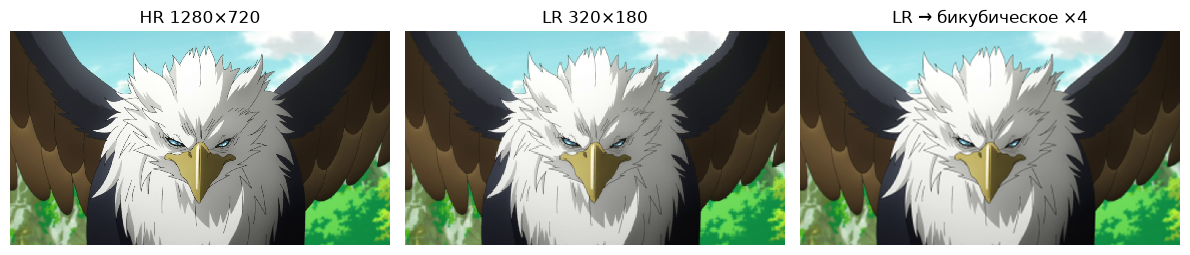

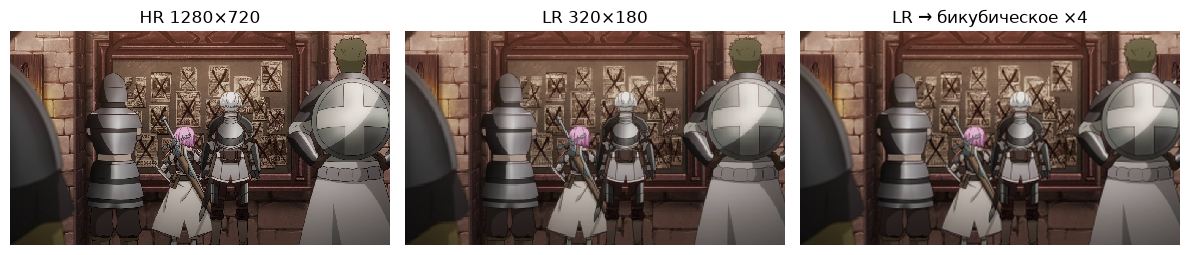

In [17]:
for name, lr, hr in eval_pairs(DATA / "val", limit=2):
    (h, w), (lh, lw) = hr.shape[:2], lr.shape[:2]
    show_row([hr, lr, bicubic_upscale(lr, SCALE)], [f"HR {w}×{h}", f"LR {lw}×{lh}", "LR → бикубическое ×4"])

## 3. Модель

**Генератор (SRResNet):**
- свёртка 9×9;
- 16 остаточных блоков (свёртка → BatchNorm → PReLU → свёртка → BatchNorm, плюс skip-связь) и длинная skip-связь вокруг них;
- два блока увеличения ×2 через `PixelShuffle`;
- выходная свёртка 9×9.

Почти все вычисления идут в низком разрешении, поэтому сеть быстрая.

**Дискриминатор:**
- 8 свёрток с LeakyReLU и BatchNorm, число каналов растёт с 64 до 512, четыре свёртки уменьшают картинку вдвое;
- два полносвязных слоя;
- на выходе - логит «настоящее HR или результат генератора».

**Функция потерь SRGAN** = content loss + 10⁻³ · adversarial loss:
- *content loss* - MSE между признаками VGG19 (слой φ5,4) для SR и HR. Сравниваются не пиксели, а «смысловые» признаки, поэтому сеть не усредняет детали в мыльное изображение;
- *adversarial loss* - штраф за то, что дискриминатор распознал подделку. Он толкает генератор к реалистичным текстурам.


In [ ]:
class ResidualBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.body = nn.Sequential(nn.Conv2d(ch, ch, 3, padding=1), nn.BatchNorm2d(ch), nn.PReLU(),
                                  nn.Conv2d(ch, ch, 3, padding=1), nn.BatchNorm2d(ch))

    def forward(self, x):
        return x + self.body(x)


class Generator(nn.Module):

    def __init__(self, scale=4, num_blocks=16, ch=64):
        super().__init__()
        self.head = nn.Sequential(nn.Conv2d(3, ch, 9, padding=4), nn.PReLU())
        self.blocks = nn.Sequential(*[ResidualBlock(ch) for _ in range(num_blocks)])
        self.post = nn.Sequential(nn.Conv2d(ch, ch, 3, padding=1), nn.BatchNorm2d(ch))
        up = []
        for _ in range(int(np.log2(scale))):   # каждый блок — увеличение ×2
            up += [nn.Conv2d(ch, ch * 4, 3, padding=1), nn.PixelShuffle(2), nn.PReLU()]
        self.upsample = nn.Sequential(*up)
        self.tail = nn.Conv2d(ch, 3, 9, padding=4)

    def forward(self, x):
        feat = self.head(x)
        feat = feat + self.post(self.blocks(feat))
        return self.tail(self.upsample(feat))


class Discriminator(nn.Module):

    def __init__(self):
        super().__init__()
        layers = [nn.Conv2d(3, 64, 3, padding=1), nn.LeakyReLU(0.2, inplace=True)]
        for cin, cout, stride in [(64, 64, 2), (64, 128, 1), (128, 128, 2), (128, 256, 1),
                                  (256, 256, 2), (256, 512, 1), (512, 512, 2)]:
            layers += [nn.Conv2d(cin, cout, 3, stride, 1), nn.BatchNorm2d(cout), nn.LeakyReLU(0.2, inplace=True)]
        self.features = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(6)   # для патча 96×96 размер и так 6×6
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(512 * 36, 1024), nn.LeakyReLU(0.2, inplace=True),
                                        nn.Linear(1024, 1))

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))


class VGGFeatures(nn.Module):

    def __init__(self):
        super().__init__()
        self.features = vgg19(weights=VGG19_Weights.IMAGENET1K_V1).features[:36].eval().requires_grad_(False)
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        return self.features((x - self.mean) / self.std)


def save_generator(path, model):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    torch.save({"scale": SCALE, "state_dict": model.state_dict()}, path)


def load_generator(path):
    data = torch.load(path, map_location=device, weights_only=True)
    model = Generator(data["scale"])
    model.load_state_dict(data["state_dict"])
    return model.to(device).eval()


count = lambda m: sum(p.numel() for p in m.parameters())
print(f"Генератор: {count(Generator(SCALE)) / 1e6:.2f} млн параметров")
print(f"Дискриминатор: {count(Discriminator()) / 1e6:.2f} млн параметров")

Генератор: 1.55 млн параметров
Дискриминатор: 23.57 млн параметров


## 4. Метрики

- **PSNR** - попиксельная близость к эталону. Считается по яркости Y без рамки в 4 пикселя, как принято в статьях по super-resolution. Любит «гладкие» ответы, поэтому у SRGAN он обычно ниже, чем у SRResNet.
- **SSIM** - сходство локальной структуры: яркости, контраста, корреляции.
- **LPIPS** - расстояние между признаками нейросети AlexNet. Лучше остальных согласуется с тем, как качество оценивает человек. По нему выбирается лучшая SRGAN.

Большие картинки при необходимости прогоняются через генератор кусками с перекрытием, чтобы хватило видеопамяти.

In [ ]:
def rgb_to_y(t):
    return 16.0 + 65.481 * t[:, 0:1] + 128.553 * t[:, 1:2] + 24.966 * t[:, 2:3]


def _y_pair(sr, hr, border):
    sr = sr.clamp(0, 1).mul(255).round().div(255)   
    y_sr, y_hr = rgb_to_y(sr.double()), rgb_to_y(hr.double())
    return y_sr[..., border:-border, border:-border], y_hr[..., border:-border, border:-border]


def psnr_y(sr, hr):
    y_sr, y_hr = _y_pair(sr, hr, SCALE)
    mse = torch.mean((y_sr - y_hr) ** 2).item()
    return float("inf") if mse == 0 else 10 * np.log10(255 ** 2 / mse)


def ssim_y(sr, hr):
    y_sr, y_hr = _y_pair(sr, hr, SCALE)
    c1, c2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    g = torch.exp(-((torch.arange(11, dtype=torch.float64, device=sr.device) - 5) ** 2) / (2 * 1.5 ** 2))
    win = (g[:, None] * g[None, :] / g.sum() ** 2).view(1, 1, 11, 11)
    mu1, mu2 = F.conv2d(y_sr, win), F.conv2d(y_hr, win)
    s11, s22 = F.conv2d(y_sr ** 2, win) - mu1 ** 2, F.conv2d(y_hr ** 2, win) - mu2 ** 2
    s12 = F.conv2d(y_sr * y_hr, win) - mu1 * mu2
    return (((2 * mu1 * mu2 + c1) * (2 * s12 + c2)) / ((mu1 ** 2 + mu2 ** 2 + c1) * (s11 + s22 + c2))).mean().item()


def make_lpips():
    try:
        import lpips
    except ImportError:
        print("Пакет lpips не установлен: LPIPS считаться не будет.")
        return None
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)  
        return lpips.LPIPS(net="alex", verbose=False).to(device).eval()


LPIPS_FN = make_lpips()


@torch.no_grad()
def lpips_value(sr, hr):
    return LPIPS_FN(sr.clamp(0, 1) * 2 - 1, hr * 2 - 1).item() if LPIPS_FN is not None else float("nan")


@torch.no_grad()
def upscale(model, lr, tile=0, overlap=32):

    def run(x):
        with torch.autocast(device.type, dtype=torch.bfloat16, enabled=AMP):
            return model(x).float().clamp(0, 1)

    _, _, h, w = lr.shape
    if tile <= 0 or (h <= tile and w <= tile):
        return run(lr)
    out = lr.new_zeros(1, 3, h * SCALE, w * SCALE)
    for y in range(0, h, tile):
        for x in range(0, w, tile):
            y0, x0 = max(y - overlap, 0), max(x - overlap, 0)
            patch = run(lr[..., y0 : min(y + tile + overlap, h), x0 : min(x + tile + overlap, w)])
            th, tw = min(tile, h - y) * SCALE, min(tile, w - x) * SCALE
            oy, ox = (y - y0) * SCALE, (x - x0) * SCALE
            out[..., y * SCALE : y * SCALE + th, x * SCALE : x * SCALE + tw] = patch[..., oy : oy + th, ox : ox + tw]
    return out


@torch.no_grad()
def evaluate_pairs(model, pairs, method="model"):
    ps, ss, lp = [], [], []
    for _, lr, hr in pairs:
        hr_t = to_tensor(hr).to(device)
        sr_t = (to_tensor(bicubic_upscale(lr, SCALE)).to(device) if method == "bicubic"
                else upscale(model, to_tensor(lr).to(device)))
        ps.append(psnr_y(sr_t, hr_t))
        ss.append(ssim_y(sr_t, hr_t))
        lp.append(lpips_value(sr_t, hr_t))
    return {"psnr": float(np.mean(ps)), "ssim": float(np.mean(ss)), "lpips": float(np.mean(lp))}


def detail_crop(img, size):
    h, w = img.shape[:2]
    size = min(size, h, w)
    cands = [(int(y), int(x)) for y in np.linspace(0, h - size, 3) for x in np.linspace(0, w - size, 3)]
    y, x = max(cands, key=lambda p: cv2.cvtColor(img[p[0] : p[0] + size, p[1] : p[1] + size], cv2.COLOR_RGB2GRAY).std())
    return (y, x), size


def labeled_grid(labels, rows, pad=4, band=28):
    h, w = rows[0][0].shape[:2]
    grid = np.full((band + len(rows) * (h + pad), len(labels) * (w + pad) - pad, 3), 255, np.uint8)
    for j, text in enumerate(labels):
        cv2.putText(grid, text, (j * (w + pad) + 6, band - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 1, cv2.LINE_AA)
    for i, row in enumerate(rows):
        for j, img in enumerate(row):
            grid[band + i * (h + pad) : band + i * (h + pad) + h, j * (w + pad) : j * (w + pad) + w] = img
    return grid

## 5. Обучение

Обе стадии обучает одна функция `train_stage`:
- **Данные.** Батчи по 16 патчей 96×96 собираются в фоновых потоках, пока GPU считает предыдущий батч.
- **Точность.** Вычисления идут в bf16 (смешанная точность): RTX 5060 так быстрее и экономнее по памяти.
- **Валидация.** Каждые 5000 итераций модель проверяется на валидации. Лучшие веса сохраняются: для SRResNet - по PSNR, для SRGAN - по LPIPS.


In [ ]:
class TrainPatches:

    def __init__(self, folder, patch, scale):
        self.files = list_images(folder)
        if not self.files:
            raise FileNotFoundError(f"Нет обучающих фрагментов в {folder}")
        self.patch, self.scale = patch, scale

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        img, p = imread_rgb(self.files[i]), self.patch
        h, w = img.shape[:2]
        if h < p or w < p:
            img = np.pad(img, ((0, max(p - h, 0)), (0, max(p - w, 0)), (0, 0)), mode="reflect")
            h, w = img.shape[:2]
        y, x = random.randint(0, h - p), random.randint(0, w - p)
        hr = img[y : y + p, x : x + p]
        if random.random() < 0.5:
            hr = hr[:, ::-1]
        if random.random() < 0.5:
            hr = hr[::-1]
        if random.random() < 0.5:
            hr = hr.transpose(1, 0, 2)
        hr = np.ascontiguousarray(hr)
        return to_tensor(downscale(hr, self.scale))[0], to_tensor(hr)[0]


def batch_stream(ds, batch_size, threads, prefetch=8):

    def make_batch():
        lr, hr = zip(*(ds[random.randrange(len(ds))] for _ in range(batch_size)))
        return torch.stack(lr), torch.stack(hr)

    pool = ThreadPoolExecutor(threads)
    queue = deque(pool.submit(make_batch) for _ in range(prefetch))
    try:
        while True:
            queue.append(pool.submit(make_batch))
            yield queue.popleft().result()
    finally:
        for f in queue:
            f.cancel()
        pool.shutdown(wait=False)


class CsvLog:

    def __init__(self, path, fields, keep_upto):
        self.path, self.fields = path, fields
        rows = []
        if keep_upto > 0 and path.exists():
            with open(path, newline="", encoding="utf-8") as f:
                rows = [r for r in csv.DictReader(f) if int(r["iter"]) <= keep_upto]
        path.parent.mkdir(parents=True, exist_ok=True)
        with open(path, "w", newline="", encoding="utf-8") as f:
            w = csv.DictWriter(f, fields, extrasaction="ignore")
            w.writeheader()
            w.writerows(rows)

    def write(self, row):
        with open(self.path, "a", newline="", encoding="utf-8") as f:
            csv.DictWriter(f, self.fields, extrasaction="ignore").writerow(
                {k: f"{v:.6g}" if isinstance(v, float) else v for k, v in row.items()})


def fmt_duration(seconds):
    m = int(seconds // 60)
    return f"{m // 60} ч {m % 60:02d} мин" if m >= 60 else f"{m} мин"


@torch.no_grad()
def save_samples(G, pairs, path, crop=64):
    rows = []
    for _, lr, hr in pairs[:3]:
        (y, x), s = detail_crop(lr, crop)
        lr_c, hr_c = lr[y : y + s, x : x + s], hr[y * SCALE : (y + s) * SCALE, x * SCALE : (x + s) * SCALE]
        rows.append([bicubic_upscale(lr_c, SCALE), to_image(upscale(G, to_tensor(lr_c).to(device))), hr_c])
    imwrite_rgb(path, labeled_grid(["Bicubic", "SR", "HR"], rows))


def train_stage(cfg, stage, init_from=None, restart=False):
    name, iterations = cfg["name"], cfg["iterations"]
    run_dir, ckpt_path = RESULTS / name, CKPT / name / "latest.pt"
    restart = restart or SMOKE
    seed_everything(SEED)
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()   # пик видеопамяти — отдельно для каждого этапа
    write_json(run_dir / "env.json", env_info())
    write_json(run_dir / "config.json", {"stage": stage, **cfg, **TRAIN_CFG})

    G = Generator(SCALE).to(device)
    opt_g = Adam(G.parameters(), lr=cfg["lr"], betas=(0.9, 0.999))
    sched_g = MultiStepLR(opt_g, cfg["milestones"], 0.1)
    D = opt_d = sched_d = vgg = None
    if stage == "srgan":
        D = Discriminator().to(device)
        opt_d = Adam(D.parameters(), lr=cfg["lr"], betas=(0.9, 0.999))
        sched_d = MultiStepLR(opt_d, cfg["milestones"], 0.1)
        vgg = VGGFeatures().to(device)

    start_iter, best, elapsed_before = 0, None, 0.0
    if ckpt_path.exists() and not restart:
        ck = torch.load(ckpt_path, map_location=device, weights_only=False)
        G.load_state_dict(ck["G"]); opt_g.load_state_dict(ck["opt_g"]); sched_g.load_state_dict(ck["sched_g"])
        if D is not None:
            D.load_state_dict(ck["D"]); opt_d.load_state_dict(ck["opt_d"]); sched_d.load_state_dict(ck["sched_d"])
        start_iter, best, elapsed_before = ck["iter"], ck["best"], ck["elapsed"]
        print(f"Продолжаю с итерации {start_iter}")
    elif init_from:
        G.load_state_dict(torch.load(WEIGHTS / f"{init_from}.pth", map_location=device, weights_only=True)["state_dict"])
        print(f"Генератор инициализирован весами {init_from}")
    if start_iter >= iterations:
        print("Этап уже обучен. Для переобучения: restart=True")
        return json.loads((run_dir / "summary.json").read_text(encoding="utf-8"))

    loss_keys = ["loss_mse"] if stage == "srresnet" else [
        "loss_g", "loss_content", "loss_adv", "loss_pixel", "loss_d", "d_real", "d_fake"]
    train_log = CsvLog(run_dir / "train_log.csv", ["iter", "lr", *loss_keys, "it_per_s", "mem_gb", "elapsed_min"],
                       start_iter)
    val_log = CsvLog(run_dir / "val_log.csv", ["iter", "psnr", "ssim", "lpips"], start_iter)

    ds = TrainPatches(DATA / "train_sub", TRAIN_CFG["patch_size"], SCALE)
    val = list(eval_pairs(DATA / "val"))
    if restart or not (run_dir / "val_bicubic.json").exists():
        write_json(run_dir / "val_bicubic.json", evaluate_pairs(None, val, method="bicubic"))
    bic = json.loads((run_dir / "val_bicubic.json").read_text(encoding="utf-8"))
    print(f"Фрагментов для обучения: {len(ds)}, val: {len(val)}. "
          f"Bicubic на val: PSNR {bic['psnr']:.2f}, SSIM {bic['ssim']:.4f}, LPIPS {bic['lpips']:.4f}")

    best_key = "lpips" if stage == "srgan" and LPIPS_FN is not None else "psnr"
    is_better = lambda v: best is None or (v < best if best_key == "lpips" else v > best)
    cw, aw, pw = cfg.get("content_weight", 1.0), cfg.get("adv_weight", 1e-3), cfg.get("pixel_weight", 0.0)
    autocast = lambda: torch.autocast(device.type, dtype=torch.bfloat16, enabled=AMP)

    def checkpoint(it):
        state = {"iter": it, "best": best, "elapsed": elapsed_before + time.time() - t_start,
                 "G": G.state_dict(), "opt_g": opt_g.state_dict(), "sched_g": sched_g.state_dict()}
        if D is not None:
            state.update(D=D.state_dict(), opt_d=opt_d.state_dict(), sched_d=sched_d.state_dict())
        ckpt_path.parent.mkdir(parents=True, exist_ok=True)
        torch.save(state, ckpt_path.with_suffix(".tmp"))
        ckpt_path.with_suffix(".tmp").replace(ckpt_path)   

    stream = batch_stream(ds, TRAIN_CFG["batch_size"], TRAIN_CFG["loader_threads"])
    acc, n_acc, done = defaultdict(float), 0, start_iter
    t_start = t_window = time.time()
    G.train()
    if D is not None:
        D.train()
    pbar = tqdm(total=iterations, initial=start_iter, desc=name, smoothing=0.05)
    try:
        for it in range(start_iter + 1, iterations + 1):
            lr_b, hr_b = (x.to(device, non_blocking=True) for x in next(stream))
            if stage == "srresnet":
                with autocast():
                    sr = G(lr_b)
                loss = F.mse_loss(sr.float(), hr_b)
                opt_g.zero_grad(set_to_none=True)
                loss.backward()
                opt_g.step()
                acc["loss_mse"] += loss.detach()
            else:
                D.requires_grad_(False)
                with autocast():
                    sr = G(lr_b)
                    f_sr = vgg(sr).float()
                    with torch.no_grad():
                        f_hr = vgg(hr_b).float()
                    fake_logit = D(sr).float()
                content = F.mse_loss(f_sr, f_hr)
                adv = F.binary_cross_entropy_with_logits(fake_logit, torch.ones_like(fake_logit))
                pixel = F.mse_loss(sr.float(), hr_b) if pw > 0 else torch.zeros((), device=device)
                loss_g = cw * content + aw * adv + pw * pixel
                opt_g.zero_grad(set_to_none=True)
                loss_g.backward()
                opt_g.step()
                D.requires_grad_(True)
                with autocast():
                    real_logit, fake_logit_d = D(hr_b).float(), D(sr.detach()).float()
                loss_d = (F.binary_cross_entropy_with_logits(real_logit, torch.ones_like(real_logit))
                          + F.binary_cross_entropy_with_logits(fake_logit_d, torch.zeros_like(fake_logit_d)))
                opt_d.zero_grad(set_to_none=True)
                loss_d.backward()
                opt_d.step()
                sched_d.step()
                for k, v in [("loss_g", loss_g), ("loss_content", content), ("loss_adv", adv), ("loss_pixel", pixel),
                             ("loss_d", loss_d), ("d_real", torch.sigmoid(real_logit).mean()),
                             ("d_fake", torch.sigmoid(fake_logit_d).mean())]:
                    acc[k] += v.detach()
            sched_g.step()
            n_acc, done = n_acc + 1, it
            pbar.update(1)

            if it % TRAIN_CFG["log_every"] == 0:
                speed = n_acc / (time.time() - t_window)
                mem = torch.cuda.max_memory_allocated() / 2 ** 30 if device.type == "cuda" else 0.0
                means = {k: float(v) / n_acc for k, v in acc.items()}
                train_log.write({"iter": it, "lr": opt_g.param_groups[0]["lr"], "it_per_s": speed, "mem_gb": mem,
                                 "elapsed_min": (elapsed_before + time.time() - t_start) / 60, **means})
                pbar.set_postfix({k: f"{v:.4g}" for k, v in means.items() if k in ("loss_mse", "loss_content", "loss_d")}
                                 | {"VRAM": f"{mem:.1f}G"})
                acc, n_acc, t_window = defaultdict(float), 0, time.time()

            if it % cfg["val_every"] == 0 or it == iterations:
                G.eval()
                res = evaluate_pairs(G, val)
                if it % cfg["sample_every"] == 0 or it == iterations:
                    save_samples(G, val, run_dir / "samples" / f"iter_{it:06d}.png")
                G.train()
                val_log.write({"iter": it, **res})
                mark = ""
                if is_better(res[best_key]):
                    best = res[best_key]
                    save_generator(WEIGHTS / f"{name}_best.pth", G)
                    mark = "  ← лучший"
                pbar.write(f"[{it}] val: PSNR {res['psnr']:.2f} дБ, SSIM {res['ssim']:.4f}, LPIPS {res['lpips']:.4f}{mark}")
                t_window = time.time() 

            if it % cfg["checkpoint_every"] == 0:
                checkpoint(it)
    except KeyboardInterrupt:
        checkpoint(done)
        print(f"Остановлено на итерации {done}. Чекпоинт сохранён — повторный запуск ячейки продолжит обучение.")
        return None
    finally:
        pbar.close()
        stream.close()

    checkpoint(iterations)
    save_generator(WEIGHTS / f"{name}.pth", G)
    total = elapsed_before + time.time() - t_start
    summary = {"name": name, "iterations": iterations, "total_time": fmt_duration(total), f"best_val_{best_key}": best}
    if device.type == "cuda":
        summary["max_vram_gb"] = round(torch.cuda.max_memory_allocated() / 2 ** 30, 2)
    write_json(run_dir / "summary.json", summary)
    del G, D, vgg
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return summary


def read_csv(path):
    if not path.exists():
        return []
    with open(path, newline="", encoding="utf-8") as f:
        return [{k: float(v) for k, v in r.items() if v} for r in csv.DictReader(f)]


def plot_curves(name):
    run = RESULTS / name
    train, val = read_csv(run / "train_log.csv"), read_csv(run / "val_log.csv")
    bic = json.loads((run / "val_bicubic.json").read_text(encoding="utf-8"))
    keys = [k for k in train[0] if k.startswith("loss_") and any(r.get(k, 0) for r in train)]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    for k in keys:
        axes[0].plot([r["iter"] for r in train], [r[k] for r in train], label=k, linewidth=1)
    axes[0].set_yscale("log")
    axes[0].set_title("Losses")
    axes[0].legend()
    for ax, key, title in ((axes[1], "psnr", "Val PSNR (Y), dB"), (axes[2], "lpips", "Val LPIPS (lower is better)")):
        ax.plot([r["iter"] for r in val], [r.get(key, np.nan) for r in val], marker=".", label=name)
        ax.axhline(bic[key], color="gray", linestyle="--", label="bicubic")
        ax.set_title(title)
        ax.legend()
    for ax in axes:
        ax.set_xlabel("iteration")
        ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(run / "curves.png", dpi=110)
    plt.show()


def show_last_sample(name):
    samples = sorted((RESULTS / name / "samples").glob("*.png"))
    if samples:
        print(f"{samples[-1].name}: Bicubic | SR | HR")
        display(Image(filename=str(samples[-1])))

### 5.1. Этап 1: SRResNet

Генератор учится только на попиксельном MSE: 150 тыс. итераций, lr = 10⁻⁴. В статье итераций 1 млн; 150 тыс. - учебный режим. 

Фрагментов для обучения: 21833, val: 20. Bicubic на val: PSNR 28.52, SSIM 0.8452, LPIPS 0.3387
[5000] val: PSNR 28.81 дБ, SSIM 0.8551, LPIPS 0.2995  ← лучший                                  
[10000] val: PSNR 29.95 дБ, SSIM 0.8868, LPIPS 0.1791  ← лучший                                  
[15000] val: PSNR 30.64 дБ, SSIM 0.9022, LPIPS 0.1471  ← лучший                                    
[20000] val: PSNR 30.94 дБ, SSIM 0.9077, LPIPS 0.1340  ← лучший                                    
[25000] val: PSNR 31.24 дБ, SSIM 0.9149, LPIPS 0.1256  ← лучший                                    
[30000] val: PSNR 31.24 дБ, SSIM 0.9136, LPIPS 0.1334  ← лучший                                    
[35000] val: PSNR 31.54 дБ, SSIM 0.9185, LPIPS 0.1259  ← лучший                                    
[40000] val: PSNR 31.69 дБ, SSIM 0.9218, LPIPS 0.1181  ← лучший                                  
[45000] val: PSNR 31.72 дБ, SSIM 0.9221, LPIPS 0.1207  ← лучший                                  
[50000] val: P

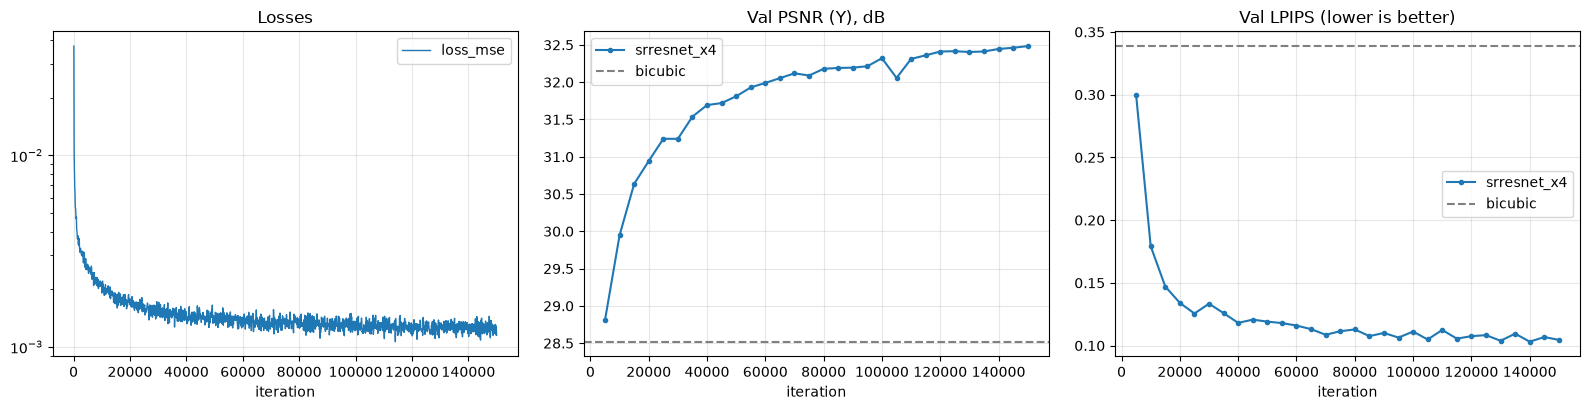

iter_150000.png: Bicubic | SR | HR


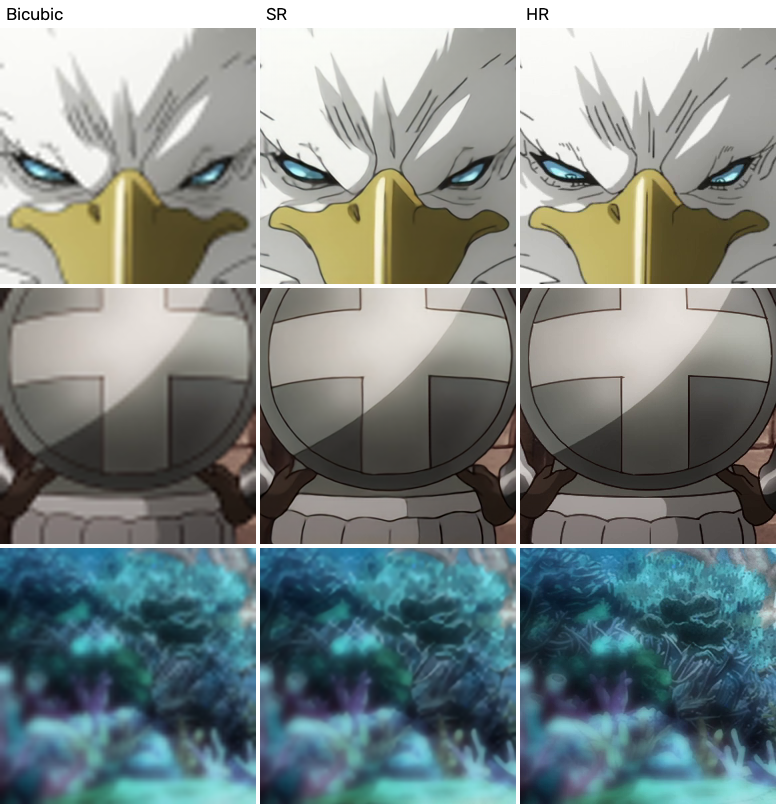

In [21]:
print(train_stage(SRRESNET_CFG, "srresnet"))
plot_curves(SRRESNET_CFG["name"])
show_last_sample(SRRESNET_CFG["name"])

### 5.2. Этап 2: SRGAN

Генератор стартует с весов SRResNet и дообучается вместе с дискриминатором на content + adversarial loss: 100 тыс. итераций, lr = 10⁻⁴, после 50 тыс. - 10⁻⁵. 

Генератор инициализирован весами srresnet_x4
Фрагментов для обучения: 21833, val: 20. Bicubic на val: PSNR 28.52, SSIM 0.8452, LPIPS 0.3387
[5000] val: PSNR 29.74 дБ, SSIM 0.9194, LPIPS 0.0879  ← лучший                                                  
[10000] val: PSNR 29.72 дБ, SSIM 0.9154, LPIPS 0.0873  ← лучший                                                  
[15000] val: PSNR 28.72 дБ, SSIM 0.9137, LPIPS 0.0813  ← лучший                                                  
[20000] val: PSNR 30.46 дБ, SSIM 0.9065, LPIPS 0.0762  ← лучший                                                  
[25000] val: PSNR 30.50 дБ, SSIM 0.9106, LPIPS 0.0777                                                             
[30000] val: PSNR 29.70 дБ, SSIM 0.9003, LPIPS 0.0804                                                             
[35000] val: PSNR 30.34 дБ, SSIM 0.9054, LPIPS 0.0755  ← лучший                                                    
[40000] val: PSNR 30.35 дБ, SSIM 0.9102, LPIPS 0.0742  ← лу

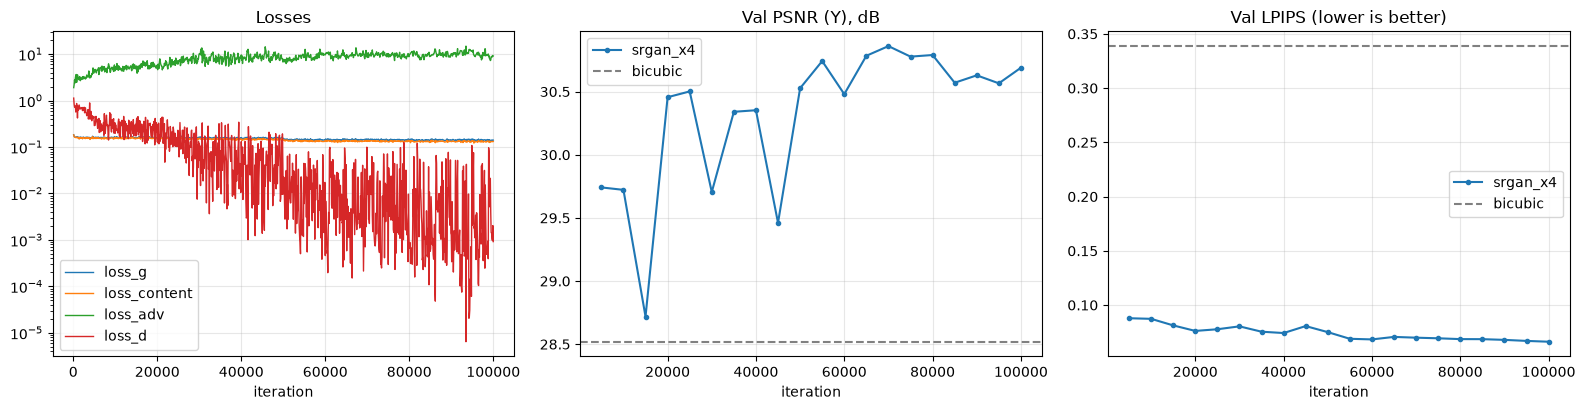

iter_100000.png: Bicubic | SR | HR


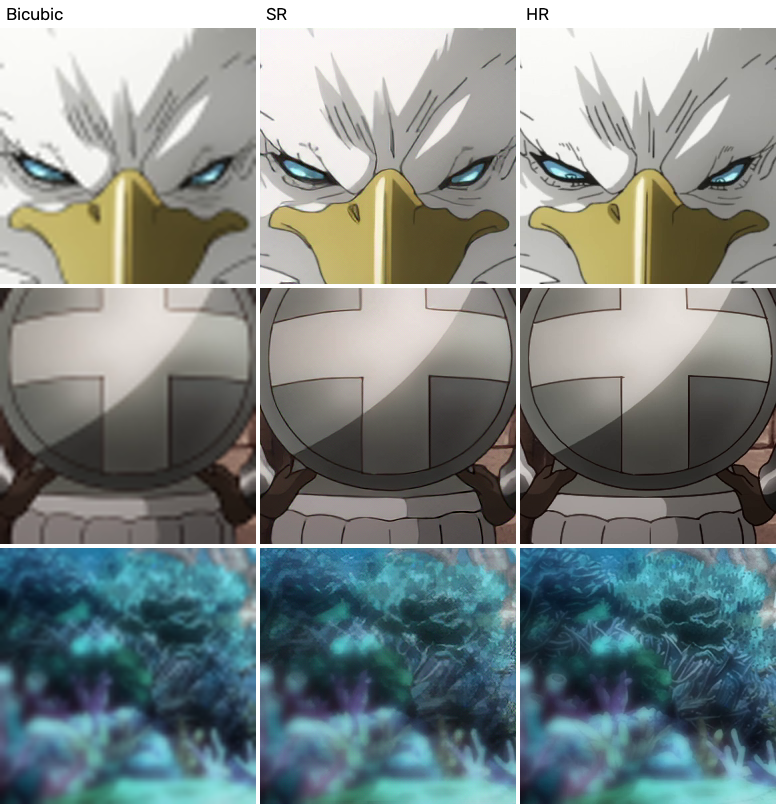

In [22]:
print(train_stage(SRGAN_CFG, "srgan", init_from=SRRESNET_CFG["name"]))
plot_curves(SRGAN_CFG["name"])
show_last_sample(SRGAN_CFG["name"])

## 6. Оценка на тестовой выборке

Сравниваются три способа получить ×4 на картинках, которые сеть не видела при обучении: бикубическая интерполяция, SRResNet и SRGAN. Ниже — таблица средних метрик и кропы самых детализированных участков.

test: 100%|██████████| 100/100 [00:42<00:00,  2.38it/s]


Тест: 100 изображений, ×4

| Метод | PSNR, дБ ↑ | SSIM ↑ | LPIPS ↓ | Время, с/изобр. |
|---|---|---|---|---|
| Bicubic | 28.58 | 0.8526 | 0.3089 | 0.003 |
| SRResNet | 32.80 | 0.9308 | 0.1009 | 0.115 |
| SRGAN | 30.67 | 0.8923 | 0.0700 | 0.030 |

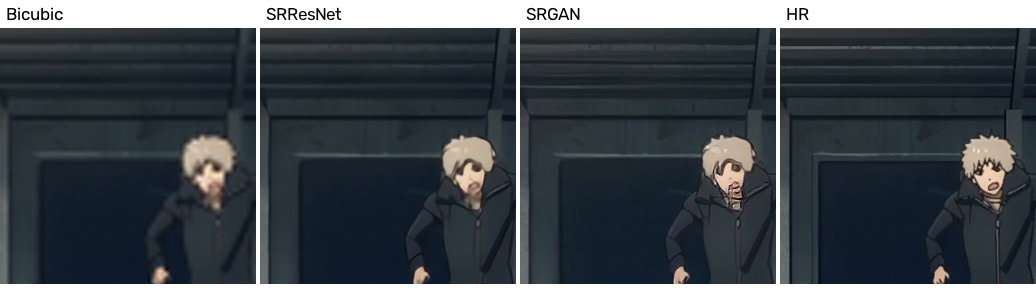

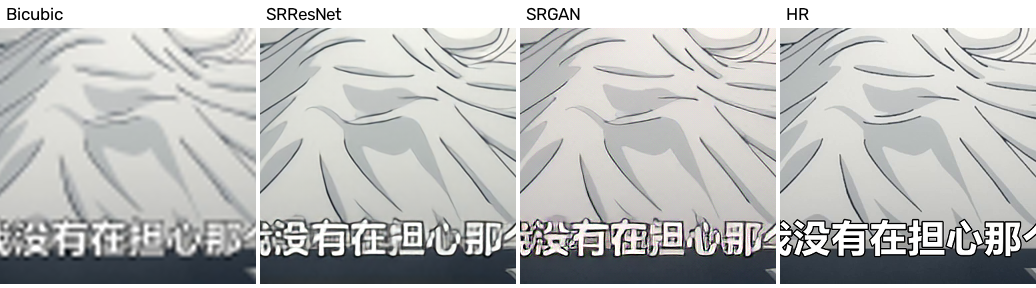

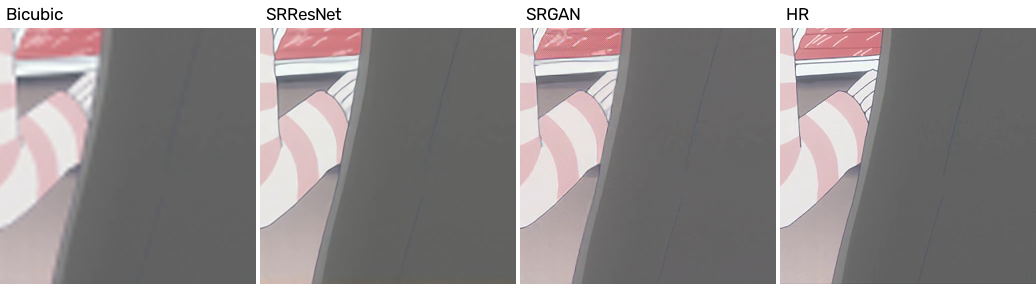

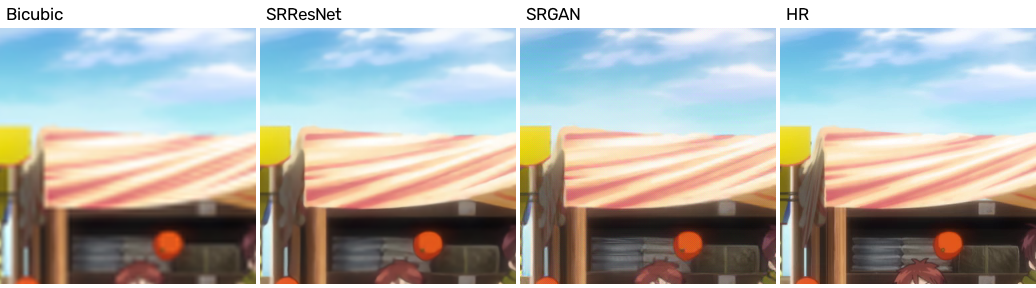

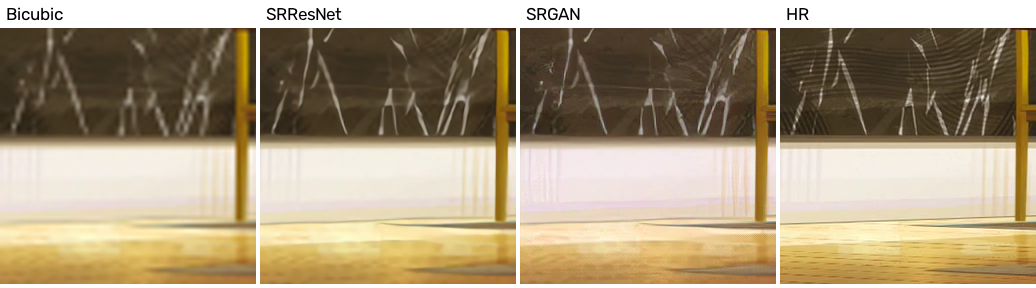

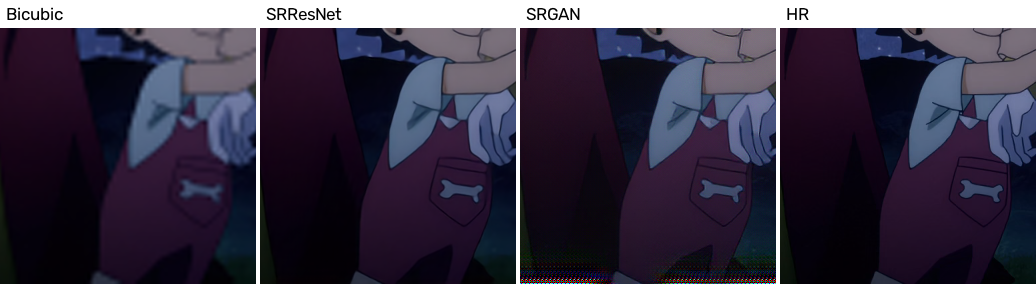

In [ ]:
@torch.no_grad()
def evaluate_test(model_names, n_grids=6, crop=64):
    out = RESULTS / "eval"
    models = {n: load_generator(WEIGHTS / f"{n}.pth") for n in model_names}
    torch.backends.cudnn.benchmark = False
    for m in models.values():
        upscale(m, torch.zeros(1, 3, 64, 64, device=device))
    labels = {"bicubic": "Bicubic", **{n: n.split("_")[0].replace("srresnet", "SRResNet").replace("srgan", "SRGAN")
                                       for n in model_names}}
    rows, grids = [], []
    for img_name, lr, hr in tqdm(list(eval_pairs(DATA / "test")), desc="test"):
        hr_t, outs = to_tensor(hr).to(device), {}
        for method in labels:
            start = time.perf_counter()
            if method == "bicubic":
                sr_t = to_tensor(bicubic_upscale(lr, SCALE)).to(device)
            else:
                sr_t = upscale(models[method], to_tensor(lr).to(device))
                if device.type == "cuda":
                    torch.cuda.synchronize()
            seconds = time.perf_counter() - start
            rows.append({"image": img_name, "method": method, "psnr": psnr_y(sr_t, hr_t), "ssim": ssim_y(sr_t, hr_t),
                         "lpips": lpips_value(sr_t, hr_t), "seconds": seconds})
            outs[method] = to_image(sr_t)
        if len(grids) < n_grids:
            (y, x), s = detail_crop(lr, crop)
            ys, xs, ss = y * SCALE, x * SCALE, s * SCALE
            row = [outs[m][ys : ys + ss, xs : xs + ss] for m in labels] + [hr[ys : ys + ss, xs : xs + ss]]
            grids.append(out / f"compare_{len(grids) + 1:02d}.png")
            imwrite_rgb(grids[-1], labeled_grid([*labels.values(), "HR"], [row]))

    out.mkdir(parents=True, exist_ok=True)
    with open(out / "metrics.csv", "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, ["image", "method", "psnr", "ssim", "lpips", "seconds"])
        w.writeheader()
        w.writerows({k: f"{v:.6g}" if isinstance(v, float) else v for k, v in r.items()} for r in rows)
    table = [f"Тест: {len(rows) // len(labels)} изображений, ×{SCALE}", "",
             "| Метод | PSNR, дБ ↑ | SSIM ↑ | LPIPS ↓ | Время, с/изобр. |", "|---|---|---|---|---|"]
    for method, label in labels.items():
        rs = [r for r in rows if r["method"] == method]
        m = lambda k: np.mean([r[k] for r in rs])
        table.append(f"| {label} | {m('psnr'):.2f} | {m('ssim'):.4f} | {m('lpips'):.4f} | {m('seconds'):.3f} |")
    (out / "summary.md").write_text("\n".join(table) + "\n", encoding="utf-8")
    display(Markdown("\n".join(table)))
    for g in grids:
        display(Image(filename=str(g)))
    torch.backends.cudnn.benchmark = True


evaluate_test([SRRESNET_CFG["name"], SRGAN_CFG["name"]])

## 7. Применение к своим картинкам

<>:1: SyntaxWarning: invalid escape sequence '\m'
<>:1: SyntaxWarning: invalid escape sequence '\m'
C:\Users\user\AppData\Local\Temp\ipykernel_11480\1876331241.py:1: SyntaxWarning: invalid escape sequence '\m'
  INPUT_PATH = "C:\my_files\pictures\Geralt.jpg"


Geralt.jpg: 1080×591 → 4320×2364, сохранено в c:\my_files\programming\python\neural_networks\neural-networks\task-1-super-resolution\results\infer\Geralt_x4.png


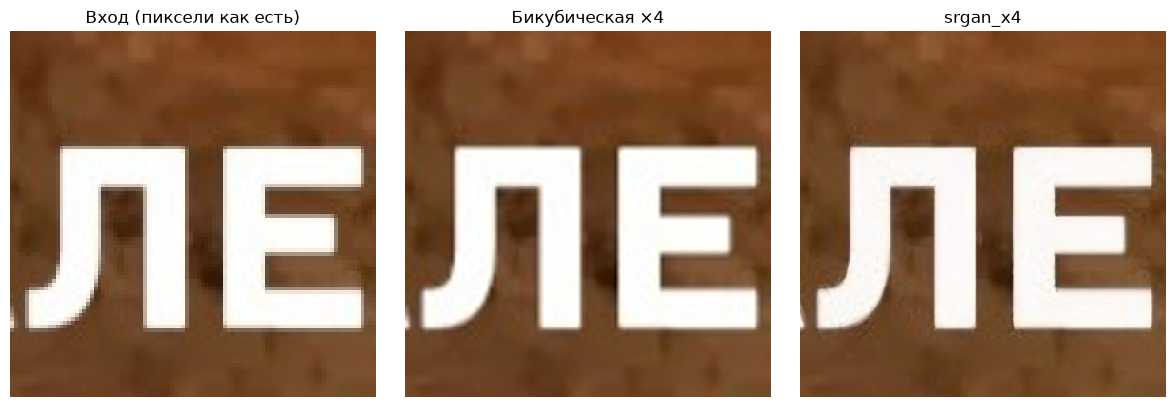

In [ ]:
INPUT_PATH = "C:\my_files\pictures\Geralt.jpg"          
MODEL = SRGAN_CFG["name"] 


def super_resolve(path, model, tile=256):
    img = imread_rgb(path)
    sr = to_image(upscale(model, to_tensor(img).to(device), tile=tile))
    dst = TASK_DIR / "results" / "infer" / f"{Path(path).stem}_x{SCALE}.png"
    imwrite_rgb(dst, sr)
    print(f"{Path(path).name}: {img.shape[1]}×{img.shape[0]} → {sr.shape[1]}×{sr.shape[0]}, сохранено в {dst}")
    return img, sr


model = load_generator(WEIGHTS / f"{MODEL}.pth")
src = Path(INPUT_PATH) if INPUT_PATH else list_images(DATA / "test" / "lr")[0]
for f in (list_images(src) if src.is_dir() else [src]):
    lr, sr = super_resolve(f, model)
    (y, x), s = detail_crop(lr, 96)
    show_row([cv2.resize(lr[y : y + s, x : x + s], None, fx=SCALE, fy=SCALE, interpolation=cv2.INTER_NEAREST),
              bicubic_upscale(lr[y : y + s, x : x + s], SCALE), sr[y * SCALE : (y + s) * SCALE, x * SCALE : (x + s) * SCALE]],
             ["Вход (пиксели как есть)", "Бикубическая ×4", MODEL])

## 8. Выводы

**Итог на тестовой выборке** (100 изображений, которые сеть не видела при обучении, увеличение ×4):

| Метод | PSNR, дБ ↑ | SSIM ↑ | LPIPS ↓ |
|---|---|---|---|
| Бикубическая интерполяция | 28,58 | 0,853 | 0,309 |
| SRResNet | **32,80** | **0,931** | 0,101 |
| SRGAN | 30,67 | 0,892 | **0,070** |

1. **Обе сети заметно лучше бикубической интерполяции.**
   - SRResNet даёт +4,2 дБ PSNR.
   - LPIPS у SRGAN в 4,4 раза ниже, чем у бикубической интерполяции.
   - На картинках сравнения линии контуров у обеих сетей чёткие, без «лесенок» и размытия.
2. **Компромисс «точность - восприятие», описанный в статье, подтвердился.**
   - SRResNet минимизирует попиксельную ошибку, поэтому лучше всех по PSNR и SSIM. Но в сомнительных местах сеть «усредняет» варианты, и изображение остаётся слегка мягким.
   - SRGAN теряет 2,1 дБ PSNR, зато LPIPS у неё на 31 % ниже, чем у SRResNet: линии резче, появляются мелкие текстуры, результат визуально ближе к оригиналу.
3. **Обучение на RTX 5060 заняло около 3 часов.**
   - SRResNet: 150 тыс. итераций за 1 ч 08 мин. PSNR на валидации к концу ещё медленно рос (+0,07 дБ за последние 25 тыс. итераций), так что более долгое обучение дало бы небольшой прирост.
   - SRGAN: 100 тыс. итераций за 1 ч 46 мин. LPIPS снижался почти монотонно (от 0,088 до 0,066), а PSNR колебался - типичная нестабильность GAN-обучения.
   - Инференс - около 0,03 с на изображение тестовой выборки.

**Ограничения:**
- **Сдвиг цвета у SRGAN.** На кропах сравнения средний цвет результата отличается от оригинала до 6 уровней из 255 (лёгкий розоватый оттенок или осветление); у SRResNet - меньше 1,5. Причина: content loss по признакам VGG слабо чувствителен к абсолютному цвету.
- **Дискриминатор доминирует.** После 50 тыс. итераций он почти безошибочно отличает результат генератора от оригинала (средняя оценка «настоящести» подделки - порядка 0,001). Генератор продолжает улучшаться, но баланс сил в GAN далёк от идеала.
- **Утраченные детали не восстанавливаются, а дорисовываются.** Мелкие текстуры, которые полностью исчезают при уменьшении в 4 раза (например, сетка на полу), сеть заменяет правдоподобными, но другими деталями.
- **Модель обучена на «чистом» уменьшении.** На реальных плохих снимках с шумом, размытием и JPEG-артефактами она будет работать хуже: для них нужно обучать с такими искажениями, как в Real-ESRGAN.

**Что можно улучшить:**
- добавить к функции потерь SRGAN попиксельную L1 с небольшим весом — она удерживает цвета;
- перейти к ESRGAN: блоки RRDB без BatchNorm и релятивистский дискриминатор, который стабилизирует GAN-обучение;
- обучать на реалистичных искажениях входа.